In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Data Warehouse Multiclass.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 280985
Number of columns: 39


In [3]:
print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

First 5 rows:


,composite_key,age_level,gender,bmi_level,smoking,diabetes,age,age_normalized,bmi,hypertension,...,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,source_dataset,disease_flags,sublabel,label
0,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,9,0.080460,19.20,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
1,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,22.55,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
2,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,22.89,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
3,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,23.12,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
4,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,4,0.022989,19.61,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280985 entries, 0 to 280984
Data columns (total 39 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   composite_key         280985 non-null  object 
 1   age_level             280985 non-null  object 
 2   gender                280985 non-null  object 
 3   bmi_level             280985 non-null  object 
 4   smoking               280985 non-null  object 
 5   diabetes              280985 non-null  object 
 6   age                   280985 non-null  int64  
 7   age_normalized        280985 non-null  float64
 8   bmi                   280985 non-null  float64
 9   hypertension          280985 non-null  float64
 10  heart_disease         280985 non-null  float64
 11  HbA1c_level           280985 non-null  float64
 12  glucose               280985 non-null  float64
 13  cholesterol           280985 non-null  float64
 14  sleep_hours           280985 n

,age,age_normalized,bmi,hypertension,heart_disease,HbA1c_level,glucose,cholesterol,sleep_hours,triglycerides,blood_pressure,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl
count,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000
mean,49.665865,0.547883,27.490663,0.128218,0.073390,5.947475,135.258646,224.045525,6.954652,178.995744,149.887200,7.489127,12.465326,134.405105,89.476720,15.003336,8.480577,74.497343,64.609147,129.725919
std,21.682350,0.249222,7.040373,0.187346,0.138243,0.954072,38.477865,35.525530,1.426412,67.336085,4.148644,1.013898,0.983375,20.542140,13.667219,6.830255,2.960646,11.402996,15.938525,27.352521
min,2.000000,0.000000,10.010000,0.000000,0.000000,3.500000,70.000000,150.000000,4.000000,50.000000,120.000000,0.003647,5.000236,90.000000,60.000000,0.000000,2.000000,50.000000,30.000000,70.000000
25%,32.000000,0.344827,22.100000,0.000000,0.000000,5.384805,100.000000,202.000000,6.200000,129.000000,148.946429,7.294863,12.287763,126.000000,84.000000,12.000000,7.200000,70.000000,58.000000,118.000000
50%,50.000000,0.551724,27.320000,0.071429,0.007299,5.800000,138.000000,225.000000,6.975185,179.000000,149.713320,7.458483,12.488407,134.167413,89.504587,14.982818,8.477600,74.487247,64.650655,129.983051
75%,67.000000,0.747126,32.700000,0.217063,0.115053,6.865766,160.000000,243.000000,7.700000,242.000000,150.720942,7.758562,12.686175,143.000000,95.000000,17.900000,9.800000,79.000000,72.000000,141.000000
max,89.000000,1.000000,95.690000,1.000000,1.000000,9.000000,300.000000,300.000000,10.000000,400.000000,180.000000,14.997087,19.999037,179.000000,119.000000,30.000000,15.000000,99.000000,99.000000,189.000000


In [4]:
missing = df.isnull().sum()

print("Total missing values:", missing.sum())

missing = missing[missing > 0]

if len(missing) > 0:
    missing.plot(kind="bar", figsize=(10, 5))
    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Missing Values")
    plt.xticks(rotation=90)
    plt.show()
else:
    print("No missing values found. Dataset is complete!")

Total missing values: 0
No missing values found. Dataset is complete!


Duplicate rows found: 2284
Rows before cleaning: 280985
Rows after cleaning: 278701
Duplicates remaining: 0


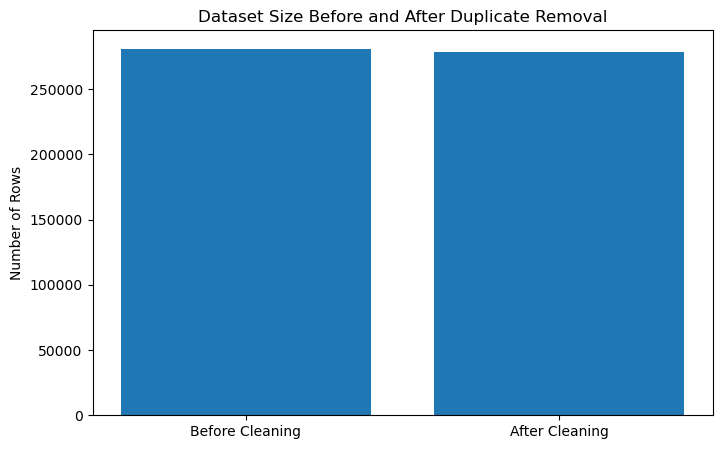

In [5]:
# Record dataset size before cleaning
rows_before = len(df)

# Count duplicate rows
duplicates = df.duplicated().sum()
print("Duplicate rows found:", duplicates)

# Remove duplicates
df = df.drop_duplicates().copy()

rows_after = len(df)
print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Duplicates remaining:", df.duplicated().sum())

# Graph: dataset size before and after cleaning
plt.figure(figsize=(8, 5))
plt.bar(
    ["Before Cleaning", "After Cleaning"],
    [rows_before, rows_after]
)
plt.title("Dataset Size Before and After Duplicate Removal")
plt.ylabel("Number of Rows")
plt.show()

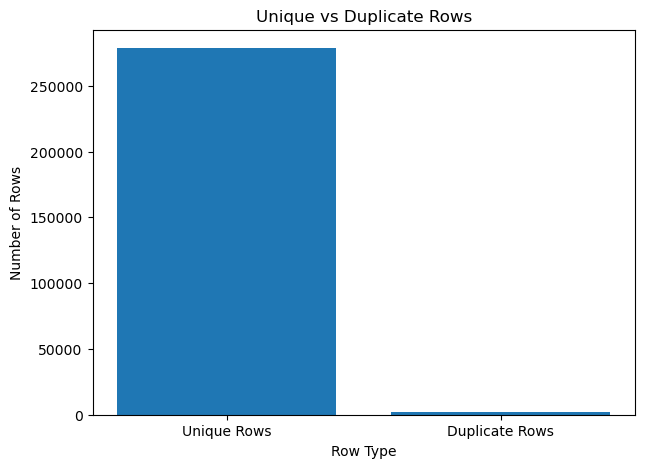

In [6]:
unique_rows = len(df)
duplicate_rows = duplicates

plt.figure(figsize=(7, 5))
plt.bar(
    ["Unique Rows", "Duplicate Rows"],
    [unique_rows, duplicate_rows]
)
plt.title("Unique vs Duplicate Rows")
plt.xlabel("Row Type")
plt.ylabel("Number of Rows")
plt.show()

Potential outliers by feature:
salt_intake           33549
alcohol_intake        32706
homocysteine_level    30989
blood_pressure        30308
crp_level             30295
ldl                   29273
systolic_bp           27371
hdl                   24946
diastolic_bp          23230
heart_rate            20939
heart_disease         10051
hypertension           8060
glucose                2028
sleep_hours            1526
bmi                    1005
dtype: int64


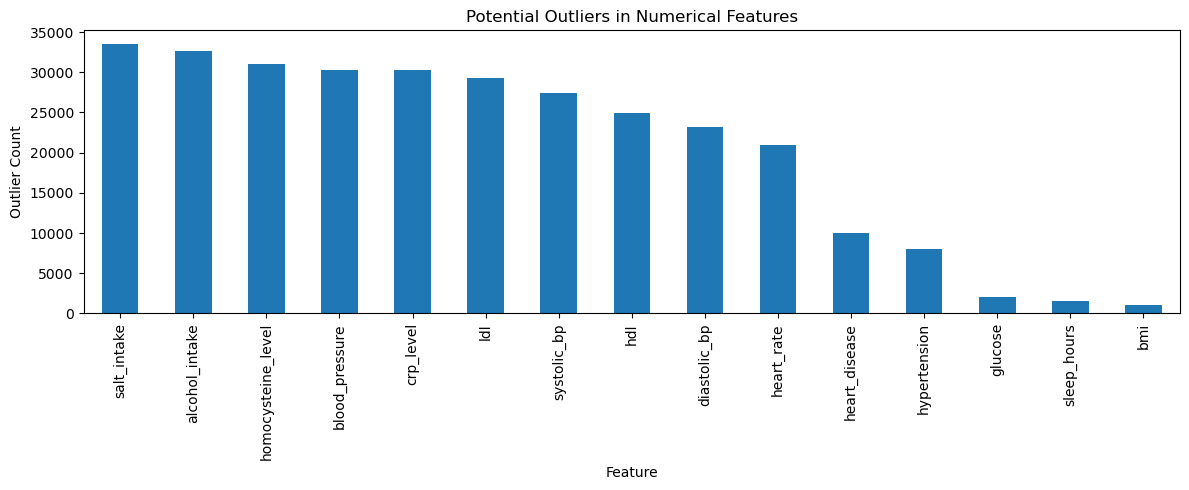

In [7]:
# Select numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Calculate IQR limits
Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Count potential outliers
outlier_counts = (
    (df[numerical_columns] < lower_limit) |
    (df[numerical_columns] > upper_limit)
).sum()

outlier_counts = outlier_counts[outlier_counts > 0].sort_values(
    ascending=False
)

print("Potential outliers by feature:")
print(outlier_counts)

# Graph
plt.figure(figsize=(12, 5))
outlier_counts.plot(kind="bar")
plt.title("Potential Outliers in Numerical Features")
plt.xlabel("Feature")
plt.ylabel("Outlier Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

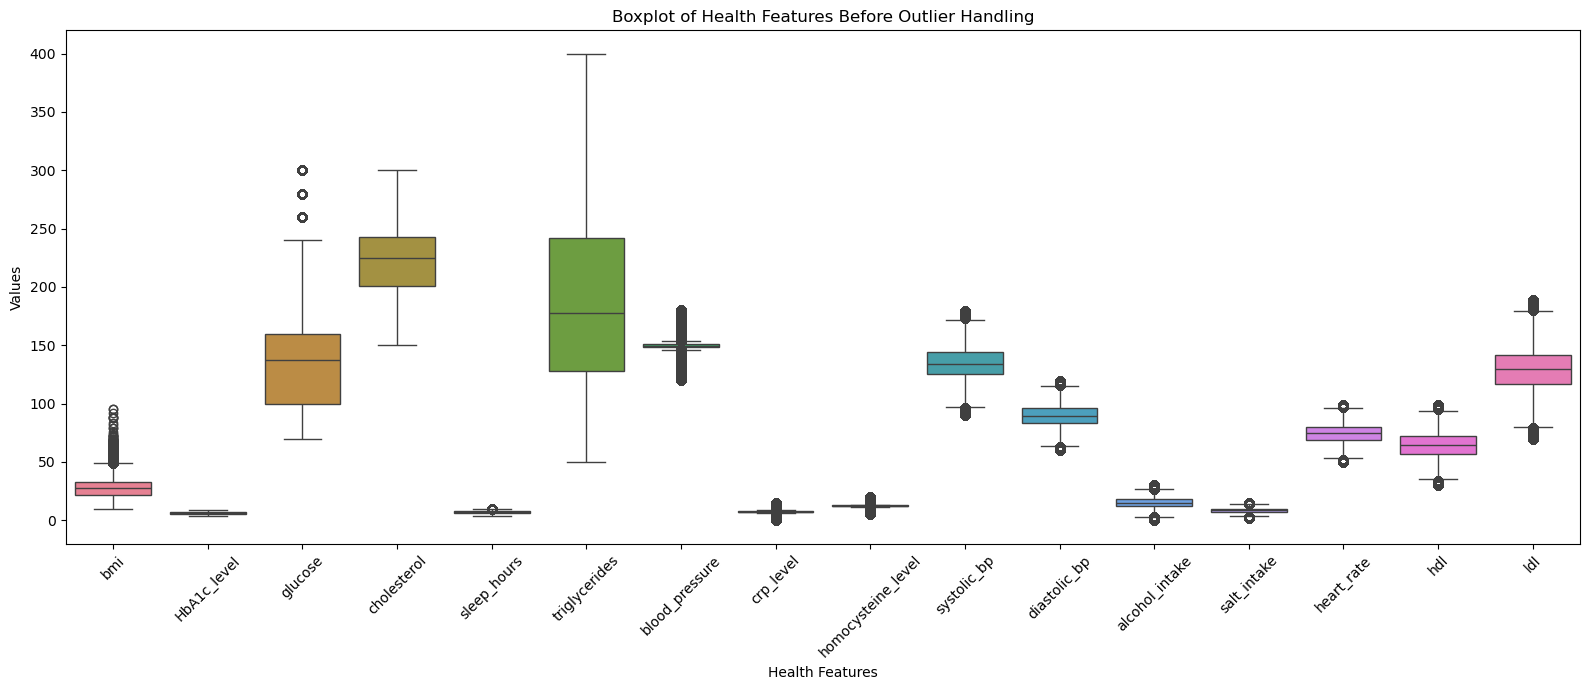

In [8]:
# Select health-related numerical features for visualization
health_columns = [
    "bmi", "HbA1c_level", "glucose", "cholesterol",
    "sleep_hours", "triglycerides", "blood_pressure",
    "crp_level", "homocysteine_level", "systolic_bp",
    "diastolic_bp", "alcohol_intake", "salt_intake",
    "heart_rate", "hdl", "ldl"
]

plt.figure(figsize=(16, 7))
sns.boxplot(data=df[health_columns])
plt.title("Boxplot of Health Features Before Outlier Handling")
plt.xlabel("Health Features")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Selected continuous health features
outlier_columns = [
    "bmi", "HbA1c_level", "glucose", "cholesterol",
    "sleep_hours", "triglycerides", "blood_pressure",
    "crp_level", "homocysteine_level", "systolic_bp",
    "diastolic_bp", "alcohol_intake", "salt_intake",
    "heart_rate", "hdl", "ldl"
]

# Cap values using IQR limits
for column in outlier_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[column] = df[column].clip(lower=lower, upper=upper)

print("Outlier capping completed.")
print("Dataset shape:", df.shape)

Outlier capping completed.
Dataset shape: (278701, 39)


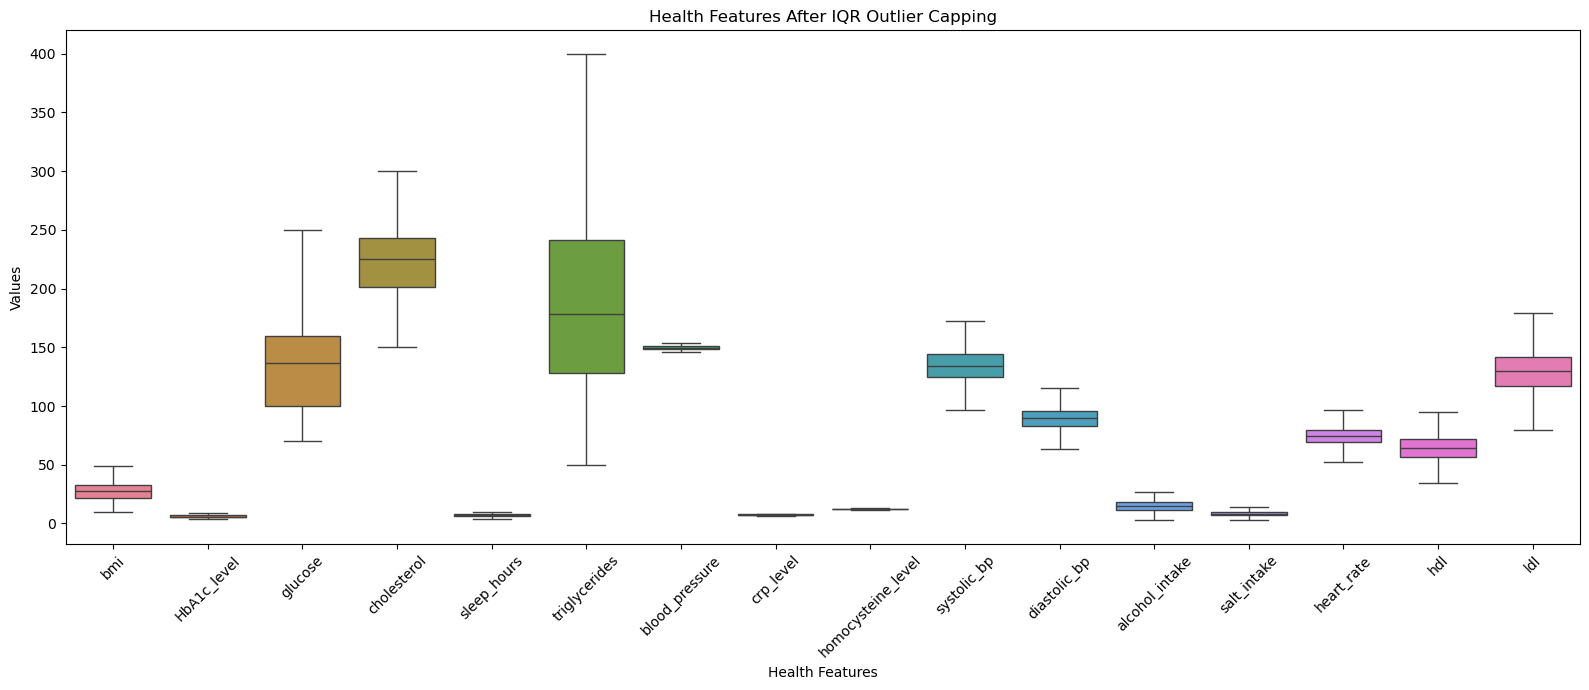

In [10]:
plt.figure(figsize=(16, 7))
sns.boxplot(data=df[outlier_columns])
plt.title("Health Features After IQR Outlier Capping")
plt.xlabel("Health Features")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

EDA

sublabel
N           104648
HY           69787
DI_HY        66472
DI           31903
HT            2583
DI_HT         1398
HT_HY         1065
DI_HT_HY       845
Name: count, dtype: int64


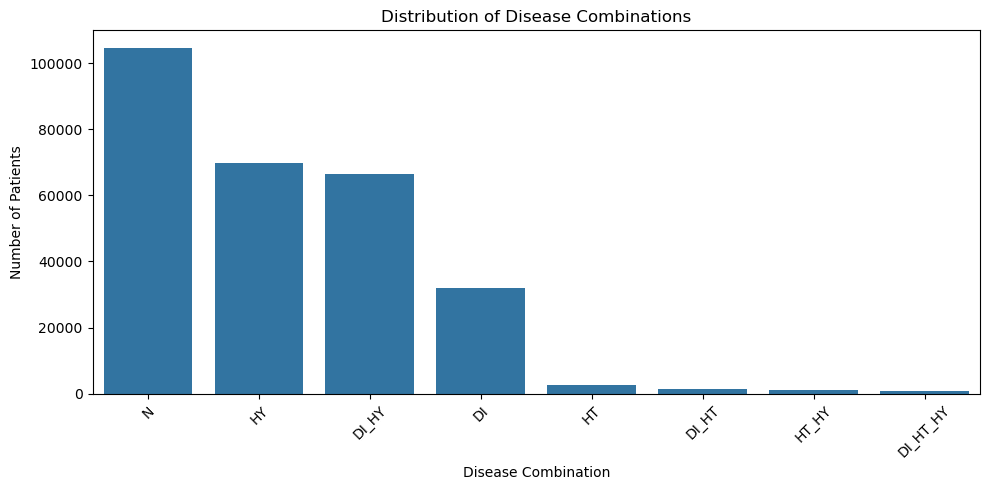

In [11]:
# Count each disease combination
print(df["sublabel"].value_counts())

# Plot distribution
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="sublabel",
    order=df["sublabel"].value_counts().index
)
plt.title("Distribution of Disease Combinations")
plt.xlabel("Disease Combination")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

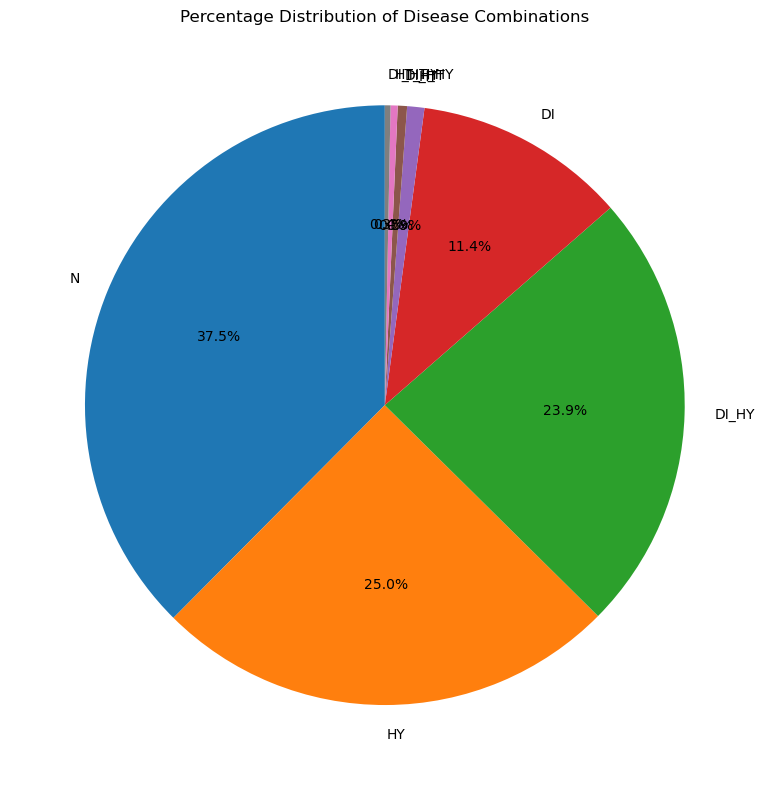

In [12]:
disease_counts = df["sublabel"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    disease_counts,
    labels=disease_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Percentage Distribution of Disease Combinations")
plt.tight_layout()
plt.show()

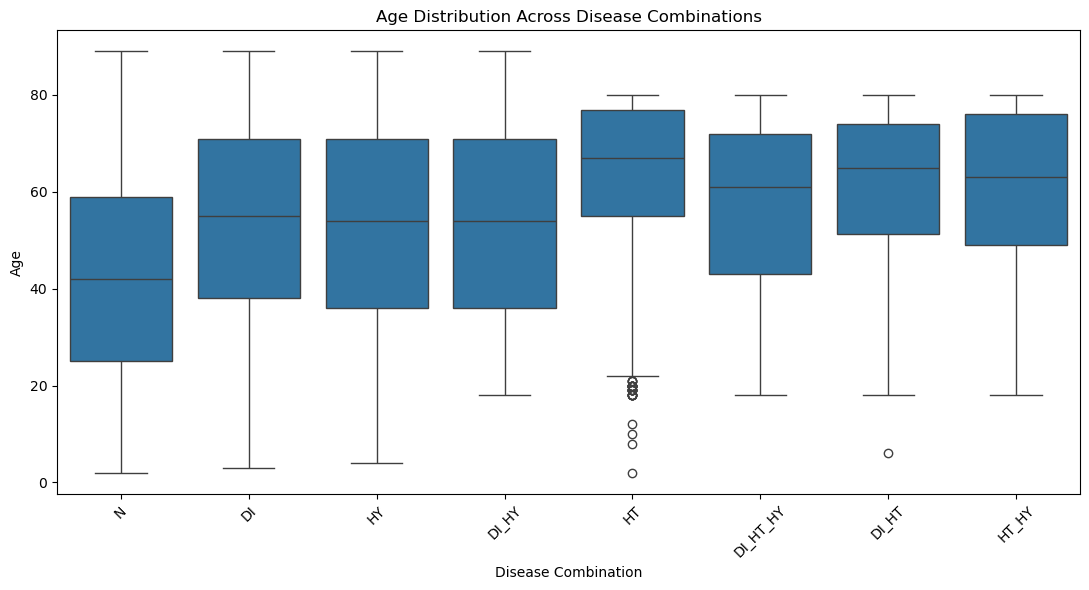

In [13]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="sublabel",
    y="age"
)

plt.title("Age Distribution Across Disease Combinations")
plt.xlabel("Disease Combination")
plt.ylabel("Age")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

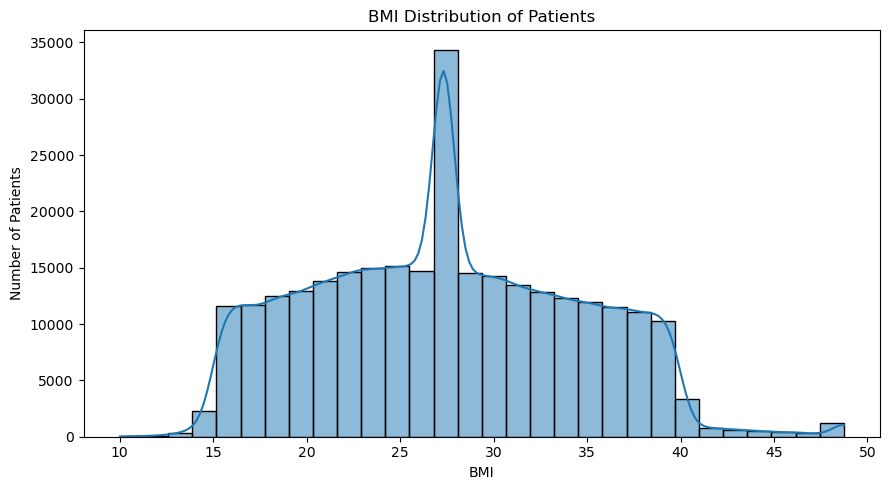

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="bmi",
    bins=30,
    kde=True
)

plt.title("BMI Distribution of Patients")
plt.xlabel("BMI")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

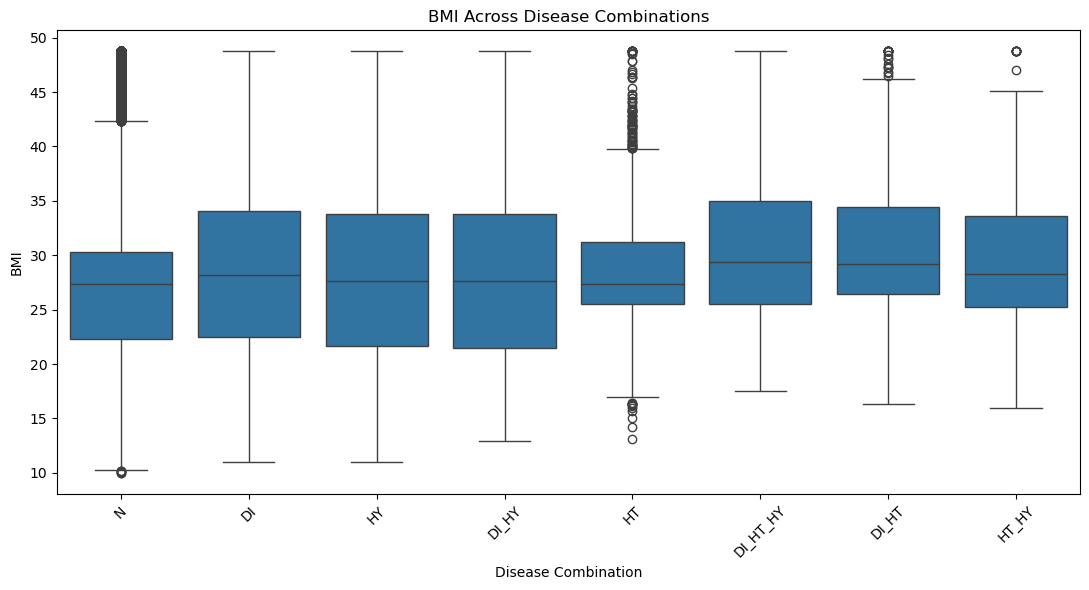

In [15]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="sublabel",
    y="bmi"
)

plt.title("BMI Across Disease Combinations")
plt.xlabel("Disease Combination")
plt.ylabel("BMI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

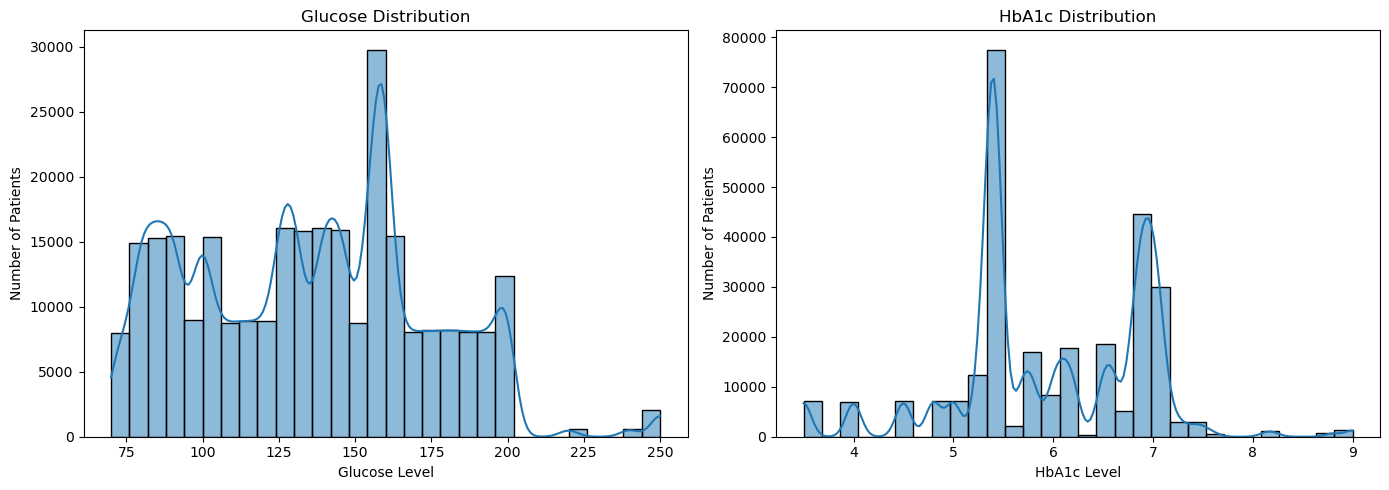

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="glucose", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Glucose Distribution")
axes[0].set_xlabel("Glucose Level")
axes[0].set_ylabel("Number of Patients")

sns.histplot(data=df, x="HbA1c_level", bins=30, kde=True, ax=axes[1])
axes[1].set_title("HbA1c Distribution")
axes[1].set_xlabel("HbA1c Level")
axes[1].set_ylabel("Number of Patients")

plt.tight_layout()
plt.show()

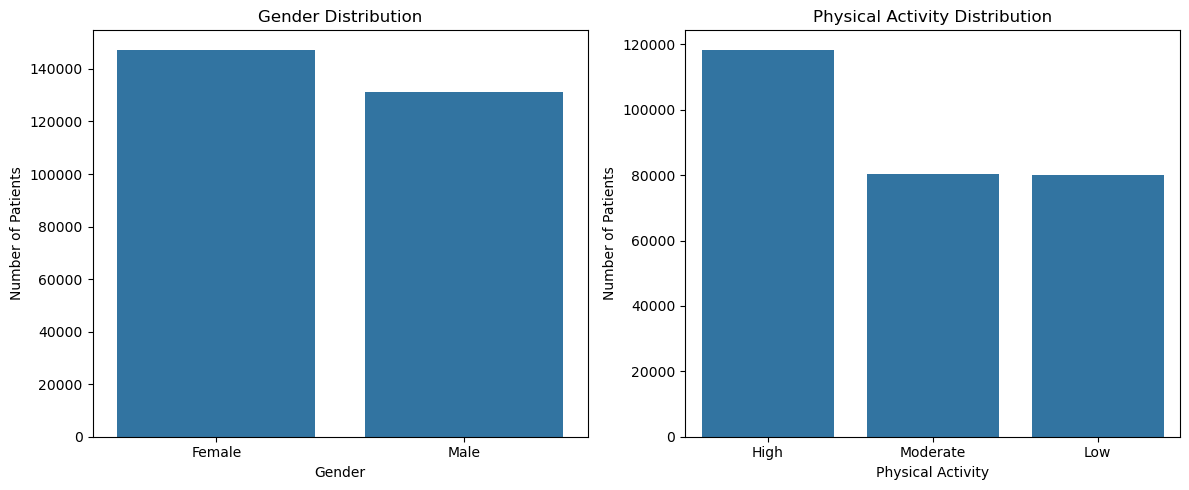

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x="gender", ax=axes[0])
axes[0].set_title("Gender Distribution")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of Patients")

sns.countplot(
    data=df,
    x="physical_activity",
    order=df["physical_activity"].value_counts().index,
    ax=axes[1]
)
axes[1].set_title("Physical Activity Distribution")
axes[1].set_xlabel("Physical Activity")
axes[1].set_ylabel("Number of Patients")

plt.tight_layout()
plt.show()

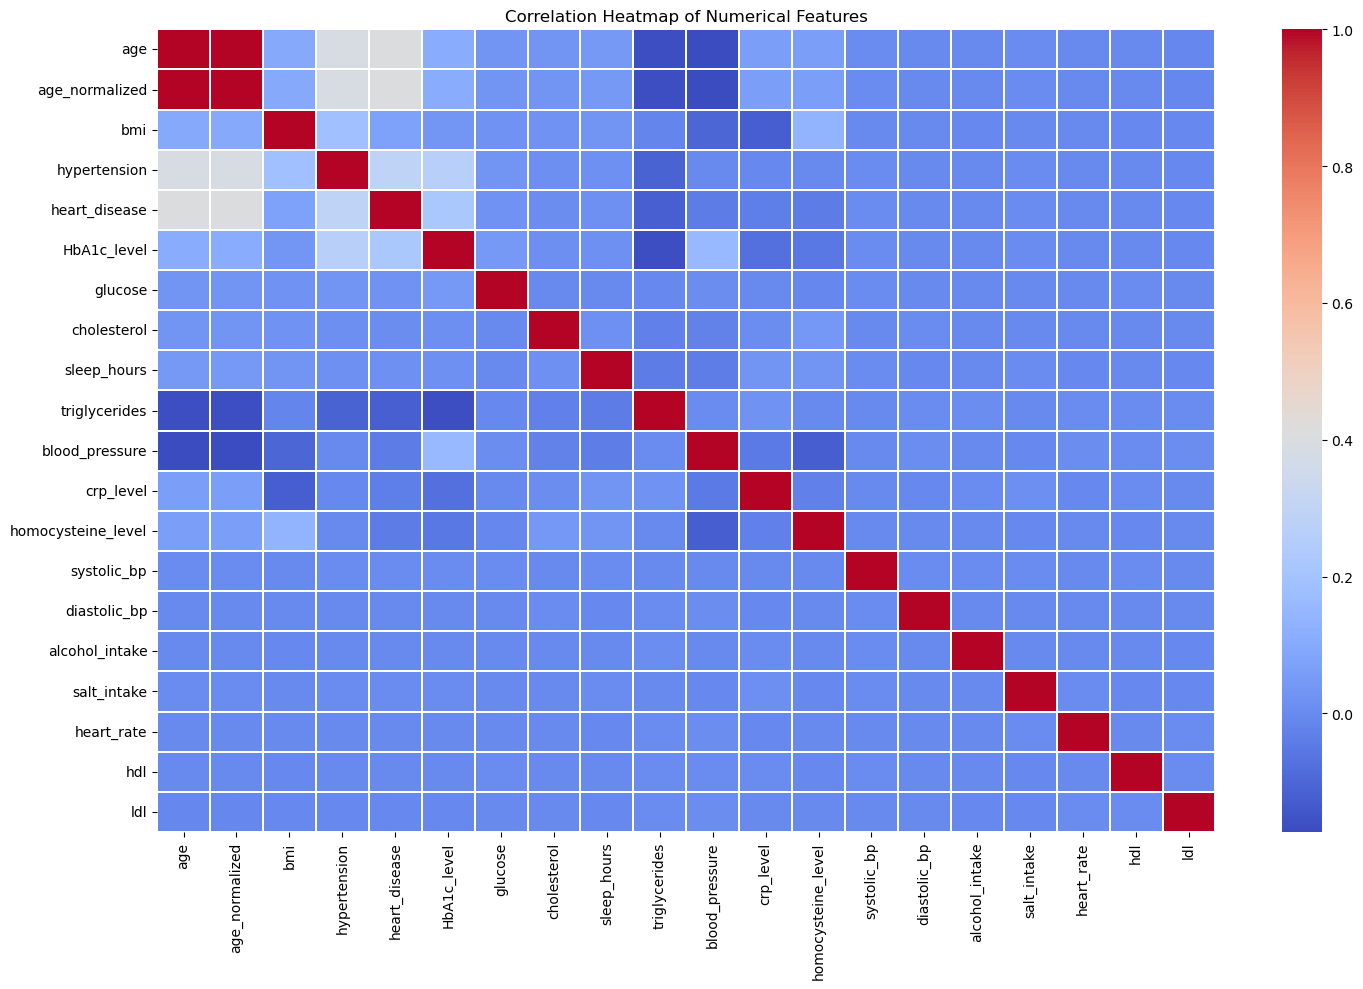

In [18]:
numerical_data = df.select_dtypes(include=["number"])

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(15, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

Feature prepration and selection

In [19]:
target = "sublabel"

leakage_columns = [
    "composite_key",
    "diabetes",
    "hypertension",
    "heart_disease",
    "disease_flags",
    "label",
    "source_dataset"
]

X = df.drop(columns=leakage_columns + [target])
y = df[target]

print("Input features:", X.shape[1])
print("Target classes:", sorted(y.unique()))

Input features: 31
Target classes: ['DI', 'DI_HT', 'DI_HT_HY', 'DI_HY', 'HT', 'HT_HY', 'HY', 'N']


In [20]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features after encoding:", X.shape[1])
display(X.head())

Features after encoding: 41


,age,age_normalized,bmi,HbA1c_level,glucose,cholesterol,sleep_hours,triglycerides,blood_pressure,crp_level,...,stress_level_Medium,low_hdl_cholesterol_Yes,high_ldl_cholesterol_Yes,high_blood_pressure_Yes,sugar_consumption_Low,sugar_consumption_Medium,education_level_Secondary,education_level_Tertiary,employment_status_Retired,employment_status_Unemployed
0,9,0.080460,19.20,5.8,158.0,214.703704,6.864403,246.703704,152.481481,8.219098,...,0,1,1,0,1,0,0,0,1,0
1,3,0.011494,22.55,6.6,159.0,214.703704,6.864403,246.703704,152.481481,8.219098,...,0,1,1,0,1,0,0,0,1,0
2,3,0.011494,22.89,4.0,126.0,214.703704,6.864403,246.703704,152.481481,8.219098,...,0,1,1,0,1,0,0,0,1,0
3,3,0.011494,23.12,6.2,85.0,214.703704,6.864403,246.703704,152.481481,8.219098,...,0,1,1,0,1,0,0,0,1,0
4,4,0.022989,19.61,5.7,155.0,214.703704,6.864403,246.703704,152.481481,8.219098,...,0,1,1,0,1,0,0,0,1,0


Train-test split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (222960, 41)
Testing data: (55741, 41)


In [22]:
feature_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

feature_model.fit(X_train, y_train)

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 20 features:")
display(feature_importance.head(20))

Top 20 features:


,Feature,Importance
3,HbA1c_level,0.184109
2,bmi,0.085082
4,glucose,0.076090
0,age,0.059916
1,age_normalized,0.058658
34,high_blood_pressure_Yes,0.043194
11,systolic_bp,0.038805
17,ldl,0.037667
13,alcohol_intake,0.037439
12,diastolic_bp,0.036577


In [23]:
# Select top 15 features using training-set importance
top_15_features = feature_importance.head(15)["Feature"].tolist()

print("Selected 15 features:")
for i, feature in enumerate(top_15_features, start=1):
    print(i, feature)

# Create reduced training and testing sets
X_train_15 = X_train[top_15_features]
X_test_15 = X_test[top_15_features]

print("\nTraining shape:", X_train_15.shape)
print("Testing shape:", X_test_15.shape)

Selected 15 features:
1 HbA1c_level
2 bmi
3 glucose
4 age
5 age_normalized
6 high_blood_pressure_Yes
7 systolic_bp
8 ldl
9 alcohol_intake
10 diastolic_bp
11 hdl
12 heart_rate
13 blood_pressure
14 triglycerides
15 salt_intake

Training shape: (222960, 15)
Testing shape: (55741, 15)


In [ ]:
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

final_model.fit(X_train_15, y_train)

print("Random Forest trained using 15 features!")

In [ ]:
y_pred_15 = final_model.predict(X_test_15)

accuracy_15 = accuracy_score(y_test, y_pred_15)
f1_macro_15 = f1_score(
    y_test, y_pred_15,
    average="macro",
    zero_division=0
)
f1_weighted_15 = f1_score(
    y_test, y_pred_15,
    average="weighted",
    zero_division=0
)

print("15-Feature Random Forest Results")
print("-" * 35)
print(f"Accuracy:   {accuracy_15:.4f} ({accuracy_15 * 100:.2f}%)")
print(f"Macro F1:   {f1_macro_15:.4f}")
print(f"Weighted F1: {f1_weighted_15:.4f}")

In [ ]:
print(classification_report(
    y_test,
    y_pred_15,
    zero_division=0
))

In [ ]:
cm = confusion_matrix(y_test, y_pred_15, labels=final_model.classes_)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=final_model.classes_,
    yticklabels=final_model.classes_
)
plt.title("Confusion Matrix - 15 Feature Random Forest")
plt.xlabel("Predicted Disease Combination")
plt.ylabel("Actual Disease Combination")
plt.tight_layout()
plt.show()

In [ ]:
# Predict using the 41-feature model
y_pred_41 = feature_model.predict(X_test)

# Calculate evaluation metrics
accuracy_41 = accuracy_score(y_test, y_pred_41)

macro_f1_41 = f1_score(
    y_test, y_pred_41,
    average="macro",
    zero_division=0
)

weighted_f1_41 = f1_score(
    y_test, y_pred_41,
    average="weighted",
    zero_division=0
)

# Compare both models
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Weighted F1"],
    "41 Features": [accuracy_41, macro_f1_41, weighted_f1_41],
    "15 Features": [accuracy_15, f1_macro_15, f1_weighted_15]
})

display(comparison.round(4))

In [ ]:
comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Random Forest: 41 Features vs 15 Features")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

In [ ]:
# Encode target classes for saving
label_encoder = LabelEncoder()
label_encoder.fit(y_train)

# Save model and selected feature names
joblib.dump(final_model, "best_model.pkl")
joblib.dump(top_15_features, "feature_columns.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Final model saved successfully!")
print("Selected features saved successfully!")
print("Label encoder saved successfully!")

In [ ]:
import os

for file in [
    "best_model.pkl",
    "feature_columns.pkl",
    "label_encoder.pkl"
]:
    print(file, "Saved" if os.path.exists(file) else "Missing")

In [ ]:
unseen_patient = pd.DataFrame([{
    "HbA1c_level": 7.2,
    "bmi": 29.5,
    "glucose": 155,
    "age": 58,
    "age_normalized": 0.65,
    "high_blood_pressure_Yes": 1,
    "systolic_bp": 145,
    "ldl": 150,
    "alcohol_intake": 10.0,
    "diastolic_bp": 92,
    "hdl": 42,
    "heart_rate": 82,
    "blood_pressure": 145,
    "triglycerides": 190,
    "salt_intake": 8.0
}])

# Ensure the feature order matches training
unseen_patient = unseen_patient[top_15_features]

print("Synthetic patient input:")
display(unseen_patient)


In [ ]:
prediction = final_model.predict(unseen_patient)[0]

print("Predicted disease combination:", prediction)

if hasattr(final_model, "predict_proba"):
    probabilities = final_model.predict_proba(unseen_patient)[0]

    probability_table = pd.DataFrame({
        "Disease Combination": final_model.classes_,
        "Probability (%)": (probabilities * 100).round(2)
    }).sort_values("Probability (%)", ascending=False)

    print("\nPrediction probabilities:")
    display(probability_table)

In [ ]:
# Enter patient details
age = float(input("Enter age: "))
bmi = float(input("Enter BMI: "))
hba1c = float(input("Enter HbA1c level: "))
glucose = float(input("Enter glucose level: "))
high_bp = input("High blood pressure? (yes/no): ").strip().lower()
systolic = float(input("Enter systolic blood pressure: "))
diastolic = float(input("Enter diastolic blood pressure: "))
blood_pressure = float(input("Enter blood pressure feature value: "))
ldl = float(input("Enter LDL cholesterol: "))
hdl = float(input("Enter HDL cholesterol: "))
triglycerides = float(input("Enter triglycerides: "))
alcohol = float(input("Enter alcohol intake: "))
salt = float(input("Enter salt intake: "))
heart_rate = float(input("Enter heart rate: "))

# Prepare the patient data
patient = pd.DataFrame([{
    "HbA1c_level": hba1c,
    "bmi": bmi,
    "glucose": glucose,
    "age": age,
    "age_normalized": (age - df["age"].min()) / (df["age"].max() - df["age"].min()),
    "high_blood_pressure_Yes": int(high_bp == "yes"),
    "systolic_bp": systolic,
    "ldl": ldl,
    "alcohol_intake": alcohol,
    "diastolic_bp": diastolic,
    "hdl": hdl,
    "heart_rate": heart_rate,
    "blood_pressure": blood_pressure,
    "triglycerides": triglycerides,
    "salt_intake": salt
}])

# Match the exact training feature order
patient = patient[top_15_features]

# Predict
prediction = final_model.predict(patient)[0]

print("\nPredicted disease combination:", prediction)

# Display model probabilities
probabilities = final_model.predict_proba(patient)[0]

results = pd.DataFrame({
    "Disease Combination": final_model.classes_,
    "Probability (%)": (probabilities * 100).round(2)
}).sort_values("Probability (%)", ascending=False)

display(results)